# Adım 3c · Geçmiş saatleri gören model (LSTM)

*3b'de MLP her saati tek başına görüyordu ve HistGB'yi (test 2,42) geçemedi. Burada modele hedef saatin **son 12 saatini** sırayla veriyoruz.*

**Kararlar (Cengo, 2026-11-08):**
- Dizi = GFS'in tahmin saatleri. Gerçek ölçüm girmez: gün öncesinde elimizde olmaz (leakage).
- Pencere yalnız geriye bakar: hedef saat dahil 12 saat. Hedeften sonraki saatlerin GFS değeri, tahmin anımızdan sonra yayınlanıyor.
- 12 saatle başlıyoruz; 6 ve 24 saati sen ölçeceksin (7. bölüm).

Kodu bu sefer Pezo açıklamalı yazdı (yeni kavram = seviye 1). Model ve eğitim ayarları 3b'dekiyle aynı (Adam 0,001, batch 256, 64 nöron): değişen tek şey modelin geçmişi görmesi olsun ki farkı ona bağlayabilelim.

In [14]:
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

from ruzgar.data import load_aligned, split, RAW, KESIM

aligned = load_aligned()
train, test = split(aligned)
train2, val = split(train, pd.Timestamp("2025-08-01", tz="UTC"))
MAE_HISTGB = 2.42

## 1. Fikir: fotoğraf yerine kısa film

3b'de modele her örnek için **tek bir satır** veriyorduk: hedef saatin 8 sayısı (GFS hızı, saat, ay, yön, hamle). Bir fotoğraf gibi.

Şimdi her örnek **12 satırlık küçük bir tablo**: hedef saatin ve ondan önceki 11 saatin aynı 8 sayısı. 12 karelik kısa bir film şeridi gibi. Model "GFS rüzgârı son saatlerde hızla artırmış" ya da "yön kuzeye dönmüş" gibi gidişatları görebilir.

Bu pencereleri **GFS tablosundan** kesiyoruz, `aligned`'dan değil. `aligned` neredeyse GFS'in tamamı (23.448 saatin 23.433'ü): yalnız ±15 dakikada METAR ölçümü olmayan **15 saat** atılmış, 10 yerde (en uzunu 25 Aralık 2024'te 6 saat). Az, ama o 10 yerde `aligned`'da "11 satır yukarısı" 11 değil 12–16 saat önce olurdu ve model bunu fark edemezdi. GFS tablosu kesintisiz olduğu için orada "11 satır yukarısı" her zaman tam 11 saat önce.

In [15]:
gfs = pd.read_parquet(RAW / "gfs_ltbj.parquet").reset_index(drop=True)

def ozellikler(g):
    # 3b'deki 8 feature'ın aynısı; tek fark sütun adları (bu tabloda _gfs eki yok)
    saat = g["time"].dt.hour
    ay = g["time"].dt.month
    yon = np.deg2rad(g["dir_deg"])
    X = pd.DataFrame(index=g.index)
    X["gfs"] = g["speed_kn"]
    X["saat_sin"] = np.sin(2 * np.pi * saat / 24)
    X["saat_cos"] = np.cos(2 * np.pi * saat / 24)
    X["ay_sin"] = np.sin(2 * np.pi * ay / 12)
    X["ay_cos"] = np.cos(2 * np.pi * ay / 12)
    X["u_ruzgar"] = g["speed_kn"] * np.sin(yon)
    X["v_ruzgar"] = g["speed_kn"] * np.cos(yon)
    X["hamle_gfs"] = g["gust_kn"]
    return X

F = ozellikler(gfs)                                # her GFS saati için 8 sayı
konum = pd.Series(gfs.index, index=gfs["time"])    # saat -> GFS tablosundaki satır numarası
F.shape

(23448, 8)

### Pencereyi kesmenin hilesi

Hedef saat GFS tablosunun 20. satırıysa, 4 saatlik pencere 17, 18, 19 ve 20. satırlardır. Bunu her hedef için tek tek döngüyle yapmak yerine numpy'a bir seferde yaptırıyoruz. Önce küçük bir örnek:

- `hedefler[:, None]` sayıları alt alta dizer (sütun yapar).
- `np.arange(-3, 1)` → `[-3, -2, -1, 0]`.
- İkisini toplayınca numpy her hedefe her farkı ekler, ortaya bir tablo çıkar. Buna **broadcasting** deniyor (3a'da görmüştük).

In [16]:
hedefler = np.array([20, 21, 50])
hedefler[:, None] + np.arange(-3, 1)

array([[17, 18, 19, 20],
       [18, 19, 20, 21],
       [47, 48, 49, 50]])

Her satır bir hedefin pencere satır numaraları. Sonra `Fs[bu_tablo]` yazınca numpy her numaranın yerine o satırın 8 sayısını koyar ve elimizde **(örnek sayısı, 12, 8)** şeklinde bir küp olur: her örnek 12×8'lik küçük bir tablo.

Tablonun en başındaki ilk 11 saatin tam penceresi yok (öncesinde GFS verisi yok); onları atıyoruz (`ok` maskesi). Kaybımız yalnız birkaç satır.

Standardizasyon 3b'deki gibi: ortalama ve standart sapma yalnız train2 dönemindeki GFS saatlerinden alınıyor.

In [17]:
def pencereler(df, ort, std, pencere=12):
    Fs = ((F - ort) / std).to_numpy(dtype=np.float32)
    idx = konum.loc[df["time"]].to_numpy()          # her hedef saatin GFS satırı
    ok = idx >= pencere - 1                          # tam penceresi olanlar
    idx = idx[ok]
    sira = idx[:, None] + np.arange(-(pencere - 1), 1)
    x = torch.tensor(Fs[sira])                       # (örnek, pencere, 8)
    y = torch.tensor(df["speed_kn_obs"].to_numpy()[ok], dtype=torch.float32).unsqueeze(1)
    return x, y

train2_donemi = gfs["time"] < pd.Timestamp("2025-08-01", tz="UTC")
ort2, std2 = F[train2_donemi].mean(), F[train2_donemi].std()

x_train2, y_train2 = pencereler(train2, ort2, std2)
x_val, y_val = pencereler(val, ort2, std2)
print("train2:", tuple(x_train2.shape), " val:", tuple(x_val.shape))

train2: (12413, 12, 8)  val: (2206, 12, 8)


Bir örneğe bakalım: val'in ilk hedefinin penceresi (standartlaştırılmadan önceki hali, okunabilsin diye). En alttaki satır hedef saat; üsttekiler önceki 11 saat.

In [18]:
i = konum.loc[val["time"].iloc[0]]
F.iloc[i - 11 : i + 1].assign(saat=gfs["time"].iloc[i - 11 : i + 1].dt.strftime("%m-%d %H:00")).set_index("saat").round(2)

,gfs,saat_sin,saat_cos,ay_sin,ay_cos,u_ruzgar,v_ruzgar,hamle_gfs
saat,,,,,,,,
07-31 13:00,9.7,-0.26,-0.97,-0.50,-0.87,-9.49,2.02,7.6
07-31 14:00,13.7,-0.50,-0.87,-0.50,-0.87,-11.98,6.64,10.3
07-31 15:00,13.9,-0.71,-0.71,-0.50,-0.87,-11.66,7.57,15.6
07-31 16:00,12.6,-0.87,-0.50,-0.50,-0.87,-9.79,7.93,16.7
07-31 17:00,7.1,-0.97,-0.26,-0.50,-0.87,-6.58,2.66,13.8
07-31 18:00,5.7,-1.00,-0.00,-0.50,-0.87,-5.28,2.14,5.8
07-31 19:00,2.6,-0.97,0.26,-0.50,-0.87,-1.93,1.74,2.3
07-31 20:00,1.6,-0.87,0.50,-0.50,-0.87,-0.00,1.60,2.3
07-31 21:00,2.3,-0.71,0.71,-0.50,-0.87,-1.18,1.97,2.5


## 2. Model: defter tutan ağ

İlk anlatımdaki benzetme: model 12 saati **sırayla** okur ve elinde küçük bir defter vardır. Her saati okuyunca deftere yazar, sonraki saati okurken deftere de bakar. Son saate gelince defterdeki not "bu 12 saatte ne oldu"nun özetidir; tahmini o nottan yapar.

Bu yapının genel adı **RNN** (recurrent = tekrarlayan; her saatte aynı ağırlıklar tekrar kullanılır).

**LSTM'in farkı tek bir şey:** deftere ne olacağına karar veren üç kapısı var.
- **Unutma kapısı:** eski notun ne kadarını sileyim? (Örnek: 10 saat önceki sakinlik artık önemsiz.)
- **Yazma kapısı:** bu saatten deftere ne ekleyeyim? (Örnek: rüzgâr birden kuzeye döndü, bunu not et.)
- **Okuma kapısı:** şu anki çıktım için defterin hangi kısmına bakayım?

Kapıların her biri 0 ile 1 arası bir sayı üretip "ne kadar geçsin" ayarlar ve bu ayarları da eğitimde kendisi öğrenir. Düz RNN'de bu kapılar yok; uzun dizilerde eski bilgi hızla siliniyor. LSTM'i bu yüzden seçtik.

Defterin büyüklüğüne **gizli boyut** (hidden size) deniyor: burada 64 sayı. 3b'deki 64 nöronun karşılığı.

In [19]:
class LSTMModel(nn.Module):
    def __init__(self, giris=8, gizli=64):
        super().__init__()
        self.lstm = nn.LSTM(giris, gizli, batch_first=True)   # defter tutan katman
        self.cikis = nn.Linear(gizli, 1)                       # son nottan tek sayı: tahmin

    def forward(self, x):
        cikti, _ = self.lstm(x)         # cikti: her saatten sonraki defter hali (örnek, 12, 64)
        son_not = cikti[:, -1, :]       # yalnız son saatten sonraki not (örnek, 64)
        return self.cikis(son_not)

model = LSTMModel()
print(model)
print("parametre sayısı:", sum(p.numel() for p in model.parameters()))

LSTMModel(
  (lstm): LSTM(8, 64, batch_first=True)
  (cikis): Linear(in_features=64, out_features=1, bias=True)
)
parametre sayısı: 19009


Satır satır:
- `batch_first=True`: verimiz (örnek, saat, feature) sırasında; PyTorch'a bunu söylüyoruz. Varsayılanı (saat, örnek, feature).
- `self.lstm(x)` iki şey döndürür: her saatten sonraki notlar ve en son iç durum. İkincisini kullanmıyoruz, o yüzden `_`'ye atıyoruz (Python'da "bunu boşver" anlamında yaygın isim).
- `cikti[:, -1, :]`: "bütün örnekler, son saat, bütün 64 sayı". `-1` Python'da listenin son elemanı demek.

Parametre sayısı ~19 bin (3b’de ~4.800): her kapının kendi ağırlıkları var. Ama aynı ağırlıklar 12 saatin hepsinde tekrar kullanılıyor; pencereyi 24 yapsak da sayı değişmez.

Şekli küçük bir örnekle görelim: 2 örnek, 12 saat, 8 feature girer, 2 tahmin çıkar.

In [20]:
with torch.no_grad():
    print(model(x_train2[:2]).shape)

torch.Size([2, 1])


## 3. Eğitim: 3b'deki fonksiyonun aynısı

Tek fark `MLP()` yerine `LSTMModel()`. Döngü, Adam, mini-batch, val takibi aynı; bir şey öğrenmişsen yeni modelde de aynen kullanılıyor demek.

Hız: bir epoch ~0,2 sn (CPU; veri küçük, GPU'ya gerek yok).

In [21]:
def egit(x, y, epoch, lr=0.001, batch_size=256, eval_x=None, eval_y=None, tohum=0, gizli=64):
    torch.manual_seed(tohum)
    model = LSTMModel(giris=x.shape[2], gizli=gizli)
    optimizer = torch.optim.Adam(model.parameters(), lr)
    yukleyici = DataLoader(TensorDataset(x, y), batch_size, shuffle=True)
    gecmis = []
    for e in range(1, epoch + 1):
        model.train()
        for xb, yb in yukleyici:
            loss = nn.functional.mse_loss(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        if eval_x is not None:
            model.eval()
            with torch.no_grad():
                gecmis.append({
                    "epoch": e,
                    "train": (model(x) - y).abs().mean().item(),
                    "val": (model(eval_x) - eval_y).abs().mean().item(),
                })
    return model, pd.DataFrame(gecmis)

model, g = egit(x_train2, y_train2, epoch=120, eval_x=x_val, eval_y=y_val)
g.iloc[[0, 9, 29, 39, 49, 59, 99, 119]].round(3)

,epoch,train,val
0,1,5.279,5.742
9,10,2.280,2.409
29,30,2.057,2.330
39,40,2.034,2.323
49,50,1.922,2.297
59,60,1.882,2.351
99,100,1.649,2.401
119,120,1.570,2.462


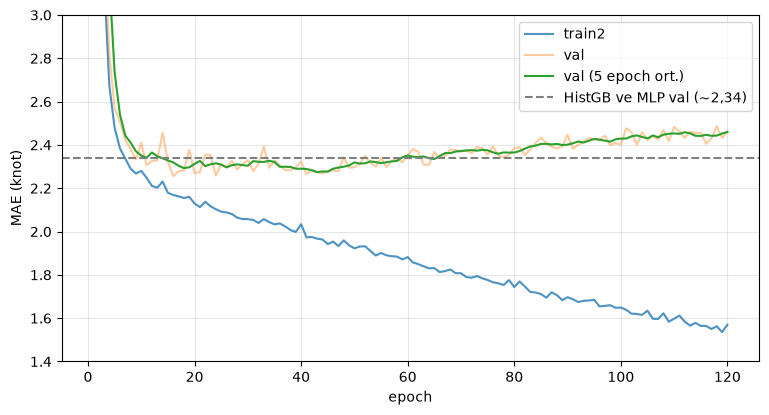

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(g["epoch"], g["train"], label="train2", alpha=0.8)
ax.plot(g["epoch"], g["val"], label="val", alpha=0.4)
ax.plot(g["epoch"], g["val"].rolling(5, center=True, min_periods=1).mean(), label="val (5 epoch ort.)")
ax.axhline(2.34, color="gray", linestyle="--", label="HistGB ve MLP val (~2,34)")
ax.set_ylim(1.4, 3.0)
ax.set_xlabel("epoch"); ax.set_ylabel("MAE (knot)")
ax.legend(); ax.grid(alpha=0.3)

**Okuma (Pezo'nun ölçümü, tohum 0):**
- Val ~40 epoch civarında **~2,27**'ye iniyor. HistGB ve MLP'nin val'i ~2,34'tü; bu ilk kez belirgin bir kazanç (~0,07 kn).
- Sonra hızlı bozuluyor: 100. epoch'ta 2,43. Train ise 1,5'e kadar iniyor. **Ezber 3b'dekinden çok daha erken ve sert:** model artık 12×8 = 96 sayıya bakıyor, ezberleyecek çok daha fazla ayrıntı var.

## 4. Tohum etkisi

3b'deki gibi: kazanç tohum gürültüsünden büyük mü?

In [23]:
for tohum in [0, 1, 2]:
    _, gt = egit(x_train2, y_train2, epoch=120, eval_x=x_val, eval_y=y_val, tohum=tohum)
    yumusak = gt["val"].rolling(5, center=True, min_periods=1).mean()
    print(f"tohum {tohum}: en iyi val {yumusak.min():.3f}, epoch {int(yumusak.idxmin()) + 1}")

tohum 0: en iyi val 2.274, epoch 43
tohum 1: en iyi val 2.272, epoch 49
tohum 2: en iyi val 2.266, epoch 36


Pezo'nun ölçümü: üç tohumda en iyi val **2,266–2,274**, en iyi epoch **36–49** arası. Tohumlar arası fark ~0,01; MLP'ye göre kazanç (~0,07) bundan çok büyük. Yani gerçek bir kazanç.

## 4b. Kuvvetli rüzgârda ne kadar iyi?

MAE bütün saatlerin ortalaması. Ama saatlerin çoğu sakin ya da orta rüzgâr; sörf için asıl önemli olan kuvvetli günler ortalamanın içinde kayboluyor.

O yüzden yalnız **gerçek rüzgârın eşiği geçtiği saatlere** bakan iki sayı daha izliyoruz:
- **MAE:** o saatlerde ortalama kaç knot yanılıyor.
- **Bias (sapma):** tahmin eksi gerçek, işaretiyle birlikte. Eksi çıkarsa **düşük tahmin ediyor** demek. MAE "ne kadar yanılıyor"u, bias "hangi yöne yanılıyor"u söyler.

Model MSE ile eğitildiği için emin olmadığında ortaya yakın bir sayı söylemeyi "güvenli" buluyor; kuvvetli günleri biraz düşük tahmin etmesini bekliyoruz. Ölçelim.

(Python: `y >= esik` her satır için True/False dizisi verir; `tahmin[maske]` yalnız True olan satırları seçer. Buna **maske** deniyor, pandas'taki `df[df["x"] > 5]`'in aynısı.)

In [24]:
def kuvvetli(model, x, y, esik=15):
    model.eval()
    with torch.no_grad():
        tahmin = model(x)
    maske = y >= esik                       # gerçek rüzgârın eşiği geçtiği saatler
    fark = tahmin[maske] - y[maske]
    return {"eşik": esik, "saat": int(maske.sum()),
            "MAE": round(fark.abs().mean().item(), 2),
            "bias": round(fark.mean().item(), 2)}

model43, _ = egit(x_train2, y_train2, epoch=43)
pd.DataFrame([kuvvetli(model43, x_val, y_val, esik) for esik in [0, 15, 20]])

,eşik,saat,MAE,bias
0,0,2206,2.28,-0.28
1,15,581,2.61,-2.16
2,20,83,4.31,-4.31


Eşik 0 = bütün saatler (normal MAE). Pezo'nun ölçümü (tohum 0, 43 epoch):
- Bütün saatlerde bias −0,3: ortalamada neredeyse dengeli.
- 15 knot üstünde (581 saat) MAE 2,61, bias **−2,2**: tahmin ortalama ~2 knot düşük.
- 20 knot üstünde (83 saat) MAE de bias de **4,3**: yani bu saatlerin neredeyse hepsinde düşük tahmin ediyor, hiç fazla söylemiyor.

Yani model ortalamada dengeli, ama en kuvvetli saatleri hâlâ eksik söylüyor. Bundan sonra her modeli MAE'nin yanında bu iki sayıyla da karşılaştıracağız. Çare seçenekleri 9. bölümde.

**Dikkat:** 20 knot üstü saat sayısı az olduğu için bu sayı gürültülü; tohumdan tohuma birkaç onda bir oynayabilir. Karşılaştırmada 15 eşiği daha güvenilir.

## 5. Kontrol: kazanç gerçekten geçmişten mi?

Belki LSTM katmanı kendi başına bir şey katıyordur ve geçmişin etkisi yoktur? Bunu ayırmak için aynı modele **1 saatlik pencere** veriyoruz: yalnız hedef saati görür, yani 3b'deki MLP ile aynı bilgiyi alır.

In [25]:
x_t1, y_t1 = pencereler(train2, ort2, std2, pencere=1)
x_v1, y_v1 = pencereler(val, ort2, std2, pencere=1)
_, g1 = egit(x_t1, y_t1, epoch=120, eval_x=x_v1, eval_y=y_v1)
yumusak1 = g1["val"].rolling(5, center=True, min_periods=1).mean()
print(f"pencere 1: en iyi val {yumusak1.min():.3f}, epoch {int(yumusak1.idxmin()) + 1}")

pencere 1: en iyi val 2.360, epoch 111


Pezo'nun ölçümü (3 tohum): pencere 1 → en iyi val **2,357–2,366**. MLP ve HistGB ile aynı seviye. Yani LSTM katmanının kendisi bir şey katmıyor; **kazancın tamamı geçmiş 11 saatten geliyor.**

Bu, projenin ilk sorusuna da bir cevap: GFS'in tek bir saatine bakmak yetmiyor; GFS'in **gidişatı** gerçek rüzgârı daha iyi anlatıyor.

## 6. Açık karar: kaç epoch?

Val dibi 36–49 arası ve sonra hızla bozuluyor. 3b'de dibin erken tarafını seçmiştik. Test için epoch sayısını sen seçeceksin; önce 7. bölümdeki pencere kıyaslamasını yap, çünkü pencere değişince dip de kayabilir.

## 7. Alıştırma: 6, 12 ve 24 saat (seviye 2, iskelet)

3b'deki lr ve batch döngülerinin aynı kalıbı. `pencereler(..., pencere=P)` pencereyi değiştiriyor. Her pencere için train2 ve val'i yeniden kesmen gerek (pencere değişince küpün şekli değişiyor). Süre: 24 saatte bir eğitim ~50 sn.

In [28]:
# denenecek pencereler
for P in [6, 12, 24]:
    x_t, y_t = pencereler(train2, ort2, std2, pencere=P)
    x_v, y_v = pencereler(val, ort2, std2, pencere=P)

    _, gt = egit(x_t, y_t, epoch=120, eval_x=x_v, eval_y=y_v)

    yumusak = gt["val"].rolling(5, center=True, min_periods=1).mean()
    en_iyi_epoch = int(yumusak.idxmin()) + 1
    print("pencere:", P, "en iyi val:", round(yumusak.min(), 3), "epoch:", en_iyi_epoch)

    # isteğe bağlı: en iyi epoch'ta yeniden eğit, kuvvetli rüzgâra bak
    m, _ = egit(x_t, y_t, epoch=en_iyi_epoch)
    print("   kuvvetli (>=15 kn):", kuvvetli(m, x_v, y_v, 15))

pencere: 6 en iyi val: 2.267 epoch: 50
   kuvvetli (>=15 kn): {'eşik': 15, 'saat': 581, 'MAE': 2.86, 'bias': -2.47}
pencere: 12 en iyi val: 2.274 epoch: 43
   kuvvetli (>=15 kn): {'eşik': 15, 'saat': 581, 'MAE': 2.61, 'bias': -2.16}
pencere: 24 en iyi val: 2.282 epoch: 27
   kuvvetli (>=15 kn): {'eşik': 15, 'saat': 581, 'MAE': 2.71, 'bias': -2.3}


**Soru (sonucu görmeden önce tahmin et):** 24 saat 12'den iyi mi olur? Daha uzun geçmiş daha çok bilgi demek, ama ezberleyecek daha çok ayrıntı da demek.

## 8. Son ölçüm: testte bir kez (seviye 2, iskelet)

Pencereyi ve epoch'u seçtikten sonra. 3b'nin 7. bölümüyle aynı protokol:
- Standardizasyonu bütün train dönemindeki GFS saatlerinden al (`gfs["time"] < KESIM`).
- Bütün train'de 3 tohumla eğit, testte bir kez ölç, üçünü de raporla ve ortalamasını al.
- Testi gördükten sonra ayar değiştirmiyoruz.

In [30]:
# seçilen ayarlar
PENCERE = 12
EPOCH = 43

# bütün train döneminin GFS istatistiği
train_donemi = gfs["time"] < KESIM
ort, std = F[train_donemi].mean(), F[train_donemi].std()

x_train, y_train = pencereler(train, ort, std, pencere=PENCERE)
x_test, y_test = pencereler(test, ort, std, pencere=PENCERE)

test_mae = []
for tohum in [0, 1, 2]:
    m, _ = egit(x_train, y_train, epoch=EPOCH, tohum=tohum)
    m.eval()
    with torch.no_grad():
        test_mae.append((m(x_test) - y_test).abs().mean().item())
    print(f"tohum {tohum}: test MAE {test_mae[-1]:.3f}  kuvvetli: {kuvvetli(m, x_test, y_test, 15)}")

print("ortalama:", round(np.mean(test_mae), 3), "  HistGB:", MAE_HISTGB)

tohum 0: test MAE 2.436  kuvvetli: {'eşik': 15, 'saat': 1844, 'MAE': 2.42, 'bias': -1.61}
tohum 1: test MAE 2.380  kuvvetli: {'eşik': 15, 'saat': 1844, 'MAE': 2.73, 'bias': -2.12}
tohum 2: test MAE 2.416  kuvvetli: {'eşik': 15, 'saat': 1844, 'MAE': 2.71, 'bias': -1.94}
ortalama: 2.41   HistGB: 2.42


In [34]:
from sklearn.ensemble import HistGradientBoostingRegressor

# HistGB: 2b'nin kazanan ayarı (ham feature, 125 ağaç), bütün train'de
def ham_ozellikler(df):
    X = pd.DataFrame(index=df.index)
    X["gfs"] = df["speed_kn_gfs"]
    X["yon"] = df["dir_deg_gfs"]
    X["hamle_gfs"] = df["gust_kn_gfs"]
    X["saat"] = df["time"].dt.hour
    X["ay"] = df["time"].dt.month
    return X

hgb = HistGradientBoostingRegressor(max_iter=125, early_stopping=False, random_state=0)
hgb.fit(ham_ozellikler(train), train["speed_kn_obs"])

# her test saati için bir satır: ay, gerçek ölçüm, modellerin hataları
karsi = pd.DataFrame({"ay": test["time"].dt.month.values,
                      "olcum": y_test.squeeze(1).numpy()})
karsi["hata_hgb"] = (hgb.predict(ham_ozellikler(test)) - karsi["olcum"]).abs()

# LSTM: 3 tohum, her birinin hatası ayrı sütun
for tohum in [0, 1, 2]:
    m, _ = egit(x_train, y_train, epoch=EPOCH, tohum=tohum)
    m.eval()
    with torch.no_grad():
        tahmin = m(x_test).squeeze(1).numpy()
    karsi[f"hata_l{tohum}"] = (tahmin - karsi["olcum"]).abs()

# üç tohumun ortalama hatası (her satırda)
karsi["hata_lstm"] = karsi[["hata_l0", "hata_l1", "hata_l2"]].mean(axis=1)

# aylık ortalama ve fark (eksi = o ay LSTM daha iyi)
aylik = karsi.groupby("ay")[["hata_lstm", "hata_hgb"]].mean()
aylik["fark"] = aylik["hata_lstm"] - aylik["hata_hgb"]
aylik.round(2)

,hata_lstm,hata_hgb,fark
ay,,,
1,2.91,2.73,0.18
2,2.61,2.69,-0.08
3,2.62,2.51,0.11
4,2.51,2.67,-0.16
5,2.26,2.22,0.04
6,2.26,2.19,0.07
7,2.66,2.64,0.01
8,2.40,2.48,-0.08
9,2.64,2.78,-0.15
